# 11 — Adaptive scoring rates

**Question:** notebooks 09 and 10 found that the biggest source of error in the Over/Under and BTTS
forecasts is drift in how many goals Serie A produces from one season to the next. Every method so
far learns its level from whole earlier seasons. **Do forecasts that follow the most recent
completed league results do better?** The hypothesis is tested, not assumed.

**Candidates** (`src/scoring_drift.py`; both settings fixed in advance: a window of the last
**200 completed matches** and **200 pseudo-matches** of shrinkage toward history):

| Method | What it is |
|---|---|
| **Adaptive event frequency** (A) | `(events in window + 200 x static frequency) / (matches in window + 200)`, per event |
| **Adaptive Poisson regression** (B) | the commit-15 Poisson regression's expected goals times `shrunk recent mean / training mean`, home and away separately; Over/Under and BTTS recomputed with the Poisson formulas |

**Existing methods**, reused from the saved commit-15 and commit-16 results on the same 2,660
fixtures: static event frequency, league average, team attack/defence, Poisson regression, direct
logistic and recalibrated Poisson regression.

**Two kinds of learning, kept apart.** *Model fitting* (static frequencies, training mean goals,
the Poisson regression) uses only seasons up to S-1 for evaluation season S. The *online scoring
statistic* is updated during S: for a fixture on date D it uses the last 200 matches dated
**strictly before D**, which may include earlier fixtures of S, just as a forecaster would have
them. It never sees the fixture itself, other fixtures on the same date, or later results.
2025-26 and 2026-27 are removed before any window is built. Bookmaker odds are never an input.

**Pre-specified decision rule** (`src/scoring_drift_backtest.py`, written before the run), judged
separately for **Over 2.5** and **BTTS** log loss. A candidate is ready for an event only if:
1. it beats the **static event frequency** with a Bonferroni-adjusted interval below 0 (family of
   8: 2 candidates x 2 events x 2 comparators);
2. its pooled log loss is not higher than the **strongest existing model** for that event;
3. it beats the static frequency in **at least 5 of 7 seasons**;
4. the gain over the static frequency survives **leaving out any one season**;
5. it is **calibrated**: slope 0.8-1.2, mean within 2 points of the observed share, at most 1 of
   10 reliability bins outside its 95% interval.

**Exploratory, not confirmatory.** These seven seasons have already shaped earlier decisions, and
the idea for this experiment came from them. A pass would still need confirmation on seasons not
yet used.

**Contents:** 1. Scoring drift in the data · 2. What the adaptive methods did · 3. Pooled and
per-season results · 4. Calibration · 5. Drift diagnostics · 6. Statistical uncertainty ·
7. Decision and conclusions

In [1]:
import time

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from src.backtest import BACKTEST_SEASONS
from src.config import FIGURES_DIR
from src.event_backtest import (
    DIRECT, EVENTS_DIR, FREQUENCY, RECALIBRATED, calibration_table, load_event_backtest, pooled_metrics,
    season_metrics, season_sensitivity,
)
from src.event_models import EVENT_NAMES, PRIMARY_EVENTS, check_valid, event_targets
from src.feature_engineering import load_features
from src.goals_backtest import (
    LEAGUE, MARKET, MODEL, TEAM, check_identical_fixtures, load_goals_backtest, market_over_under, reliability_table,
)
from src.goals_model import EVENTS
from src.scoring_drift import PRIOR_MATCHES, WINDOW_MATCHES, response_share
from src.scoring_drift_backtest import (
    ADAPTIVE_FREQUENCY, ADAPTIVE_POISSON, CANDIDATES, DRIFT_DIR, METHODS, RULE_COMPARISONS, block_errors,
    error_persistence, load_drift_backtest, phase_table, primary_comparisons, readiness, rolling_levels,
    rule_comparisons, run_scoring_drift_backtest, save_drift_backtest, season_bias, season_goal_levels,
    secondary_comparisons, strongest_existing,
)
from src.train import VALIDATION_SEASON, season_name

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

features = load_features()
if (DRIFT_DIR / "predictions.csv").exists():
    experiment = load_drift_backtest()
    print("Loaded the saved experiment from outputs/scoring_drift/ (python -m src.scoring_drift_backtest)")
else:
    start = time.time()
    experiment = run_scoring_drift_backtest(features, load_goals_backtest().predictions,
                                            load_event_backtest().predictions)
    save_drift_backtest(experiment)
    print(f"Experiment finished in {time.time() - start:.0f} seconds")

predictions, drift = experiment.predictions, experiment.drift
assert set(predictions["season"]) == set(BACKTEST_SEASONS) and predictions["season"].max() < VALIDATION_SEASON
check_identical_fixtures(predictions, METHODS)
check_valid(predictions)

# Chronology: every window ends strictly before its fixture's date, and is full (200 matches)
assert (drift["window_last_date"] < drift["date"]).all() and (drift["window_matches"] == WINDOW_MATCHES).all()
# The existing forecasts are exactly the saved commit-16 results
saved = load_event_backtest().predictions
keys = ["season", "method", "date", "home_team", "away_team"]
mine = predictions[predictions["method"].isin(saved["method"].unique())].sort_values(keys).reset_index(drop=True)
theirs = saved.sort_values(keys).reset_index(drop=True)
assert mine[keys].astype(str).equals(theirs[keys].astype(str))
print("Existing forecasts equal the commit-16 results; largest difference",
      f"{np.abs(mine[EVENT_NAMES].to_numpy() - theirs[EVENT_NAMES].to_numpy()).max():.1e}")
print(f"{(predictions['method'] == ADAPTIVE_FREQUENCY).sum():,} fixtures x {predictions['method'].nunique()} methods")
N_RESAMPLES = 10_000
SEASON_LABELS = {s: season_name(s) for s in BACKTEST_SEASONS}

Loaded the saved experiment from outputs/scoring_drift/ (python -m src.scoring_drift_backtest)
Existing forecasts equal the commit-16 results; largest difference 0.0e+00
2,660 fixtures x 8 methods


In [2]:
# --- Chart style (same as notebooks 01-10) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE_LINE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#a3a29b"
COLORS = {MODEL: "#2a78d6", DIRECT: "#1baf7a", RECALIBRATED: "#c44e9b", ADAPTIVE_FREQUENCY: "#eb6834",
          ADAPTIVE_POISSON: "#4a3aa7", LEAGUE: NEUTRAL, FREQUENCY: INK_2, TEAM: NEUTRAL}
STYLE = {LEAGUE: "--", FREQUENCY: ":"}
SHOWN = [FREQUENCY, MODEL, RECALIBRATED, DIRECT, ADAPTIVE_FREQUENCY, ADAPTIVE_POISSON]
SIDE_COLORS = {"home": "#2a78d6", "away": "#eb6834"}


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_LINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")


def legend(ax, **kwargs):
    return ax.legend(**({"frameon": False, "fontsize": 8, "labelcolor": INK_2} | kwargs))


def season_axis(ax):
    ax.set_xticks(range(len(BACKTEST_SEASONS)))
    ax.set_xticklabels([SEASON_LABELS[s] for s in BACKTEST_SEASONS], rotation=45, ha="right")


def season_bounds(ax, frame, label_y=None):
    # Vertical hairlines at the first match date of every season, with the season name
    starts = frame.groupby("season")["date"].min()
    for season, start in starts.items():
        ax.axvline(start, color=GRID, linewidth=1, zorder=0)
        if label_y is not None:
            ax.text(start, label_y, " " + season_name(season), fontsize=7.5, color=MUTED, va="top")

## 1. Scoring drift in the data

League-wide home and away goals per match in every completed season, and the training means each
backtest fold was fitted with (all seasons from 1993-94 up to S-1).

In [3]:
levels = season_goal_levels(features)
folds = experiment.folds.set_index("season")
view = levels.loc[2012:, ["home_goals", "away_goals", "total_goals", "over_2_5", "btts_yes"]].copy()
view["training home mean"] = folds["train_home_goals"]
view["training away mean"] = folds["train_away_goals"]
view.index = view.index.map(season_name)
display(view.style.format("{:.2f}", na_rep="-", subset=["home_goals", "away_goals", "total_goals",
                                                        "training home mean", "training away mean"])
        .format("{:.1%}", subset=["over_2_5", "btts_yes"])
        .set_caption("Goals per match and event shares by season (training means only for backtest seasons)"))

,home_goals,away_goals,total_goals,over_2_5,btts_yes,training home mean,training away mean
season_start,,,,,,,
2012-13,1.49,1.14,2.64,47.9%,51.1%,-,-
2013-14,1.54,1.19,2.72,49.2%,48.7%,-,-
2014-15,1.50,1.19,2.69,50.5%,56.3%,-,-
2015-16,1.47,1.11,2.58,47.4%,51.1%,-,-
2016-17,1.66,1.29,2.96,58.2%,57.4%,-,-
2017-18,1.46,1.22,2.68,52.1%,49.5%,-,-
2018-19,1.48,1.20,2.68,51.8%,53.4%,1.53,1.10
2019-20,1.62,1.42,3.04,62.9%,62.1%,1.53,1.10
2020-21,1.63,1.43,3.05,56.6%,59.7%,1.53,1.12


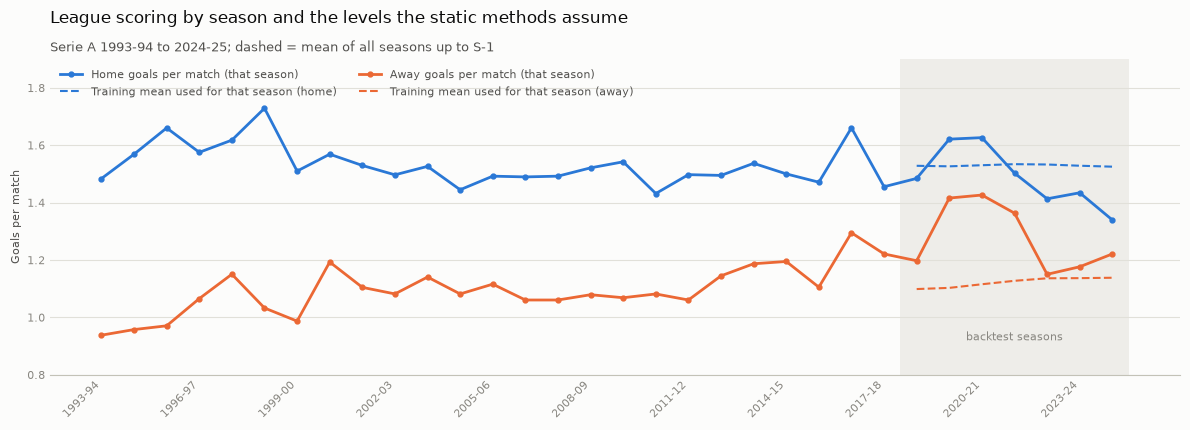

In [4]:
# Figure 64: home and away goals per match by season, with the training means of each fold
fig, ax = plt.subplots(figsize=(12, 4.4))
fig.patch.set_facecolor(SURFACE)
x = levels.index
for side in ("home", "away"):
    ax.plot(x, levels[f"{side}_goals"], color=SIDE_COLORS[side], linewidth=2, marker="o", markersize=3.5,
            label=f"{side.title()} goals per match (that season)")
    ax.plot(folds.index, folds[f"train_{side}_goals"], color=SIDE_COLORS[side], linewidth=1.5, linestyle="--",
            label=f"Training mean used for that season ({side})")
ax.axvspan(2017.5, 2024.5, color=GRID, alpha=0.5, linewidth=0)
ax.text(2021, 0.92, "backtest seasons", ha="center", fontsize=8, color=MUTED)
style_axes(ax)
ax.set_ylim(0.8, 1.9)
ax.set_xticks(x[::3])
ax.set_xticklabels([season_name(s) for s in x[::3]], rotation=45, ha="right")
ax.set_ylabel("Goals per match", fontsize=8, color=INK_2)
set_title(ax, "League scoring by season and the levels the static methods assume",
          "Serie A 1993-94 to 2024-25; dashed = mean of all seasons up to S-1")
legend(ax, loc="upper left", ncols=2)
fig.tight_layout()
save_figure(fig, "64_scoring_by_season.png")
plt.show()

In [5]:
# Within-season movement: the 200-match window at every match date (strictly earlier matches only)
rolling = rolling_levels(features, seasons=range(2016, 2025))
rolling["recent_total"] = rolling["recent_home"] + rolling["recent_away"]
rolling["level_total"] = rolling["level_home"] + rolling["level_away"]
rolling["train_total"] = rolling["train_home"] + rolling["train_away"]
# Realised goals per match in chronological blocks of 38 matches (outcomes, shown for evaluation only)
history = features[(features["season_start"].between(2016, 2024)) & features["home_goals"].notna()].copy()
history = history.sort_values(["date", "home_team", "away_team"], kind="stable")
history["block"] = history.groupby("season_start").cumcount() // 38
history["total"] = history["home_goals"] + history["away_goals"]
realised = history.groupby(["season_start", "block"]).agg(date=("date", "median"), total=("total", "mean"))
range_table = rolling.groupby("season")["recent_total"].agg(["min", "max"]).rename(index=season_name)
range_table["range"] = range_table["max"] - range_table["min"]
display(range_table.style.format("{:.2f}").set_caption(
    "Window mean of total goals per match: lowest and highest value within each season"))

,min,max,range
season,,,
2016-17,2.56,3.04,0.47
2017-18,2.46,3.19,0.72
2018-19,2.58,2.78,0.20
2019-20,2.71,3.17,0.46
2020-21,2.79,3.39,0.60
2021-22,2.63,3.21,0.58
2022-23,2.42,2.74,0.32
2023-24,2.51,2.70,0.19
2024-25,2.38,2.79,0.41


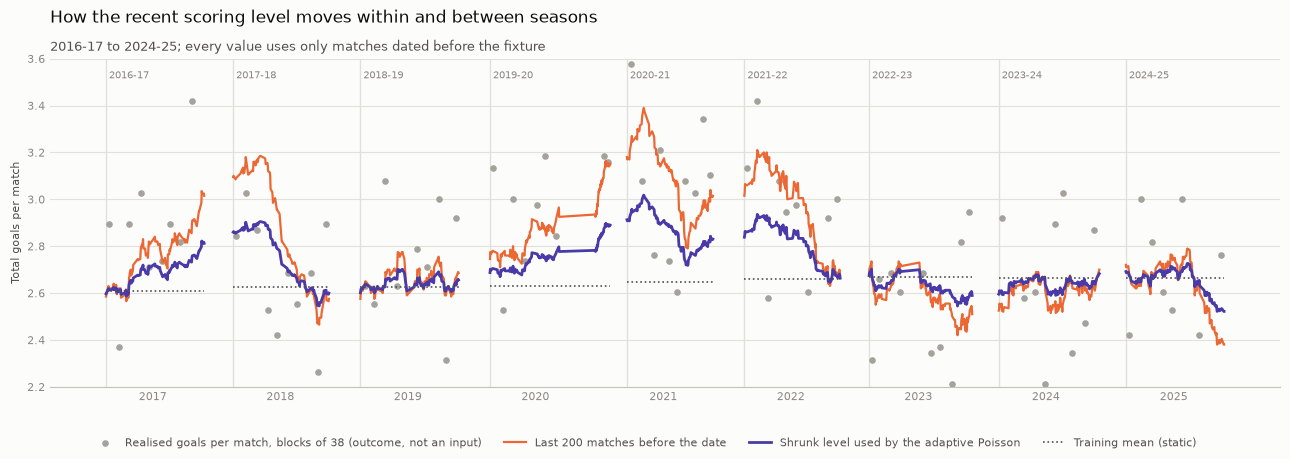

In [6]:
# Figure 65: the online window through time
fig, ax = plt.subplots(figsize=(13, 4.6))
fig.patch.set_facecolor(SURFACE)
ax.scatter(realised["date"], realised["total"], s=14, color=NEUTRAL, zorder=2,
           label="Realised goals per match, blocks of 38 (outcome, not an input)")
for season, rows in rolling.groupby("season"):
    first = season == rolling["season"].min()
    ax.plot(rows["date"], rows["recent_total"], color=COLORS[ADAPTIVE_FREQUENCY], linewidth=1.6,
            label="Last 200 matches before the date" if first else None)
    ax.plot(rows["date"], rows["level_total"], color=COLORS[ADAPTIVE_POISSON], linewidth=2,
            label="Shrunk level used by the adaptive Poisson" if first else None)
    ax.plot(rows["date"], rows["train_total"], color=INK_2, linewidth=1.2, linestyle=":",
            label="Training mean (static)" if first else None)
season_bounds(ax, rolling, label_y=3.55)
style_axes(ax)
ax.set_ylim(2.2, 3.6)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("Total goals per match", fontsize=8, color=INK_2)
set_title(ax, "How the recent scoring level moves within and between seasons",
          "2016-17 to 2024-25; every value uses only matches dated before the fixture")
fig.tight_layout(rect=(0, 0.08, 1, 1))
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=4, frameon=False, fontsize=8, labelcolor=INK_2)
save_figure(fig, "65_rolling_scoring_level.png")
plt.show()

In [7]:
# How fast can the adaptive estimate follow a lasting change? (exact for the fixed settings)
steps = [19, 38, 100, 190, 200, 380]
response = pd.DataFrame({"matches since the change": steps,
                         "about": ["2 rounds", "4 rounds", "10 rounds", "half a season", "200 matches", "a season"],
                         "share of the change absorbed": response_share(steps)})
display(response.style.format({"share of the change absorbed": "{:.0%}"}).hide(axis="index").set_caption(
    f"Window {WINDOW_MATCHES}, shrinkage {PRIOR_MATCHES:.0f} pseudo-matches; starting from a full window at the old level"))

matches since the change,about,share of the change absorbed
19,2 rounds,5%
38,4 rounds,10%
100,10 rounds,25%
190,half a season,48%
200,200 matches,50%
380,a season,50%


**Interpretation**

- **Scoring moved a lot during the backtest.** Total goals per match went from 2.68 in 2018-19 to
  3.04 and 3.05 in 2019-20 and 2020-21, then fell back to about 2.56-2.61 from 2022-23. The burst
  came mostly from away goals (1.20 to 1.43).
- **The static methods sit at the level of the 1993-onward history.** Their training means were
  about 1.53 home and 1.10-1.14 away goals per match. Away scoring has been above that mean in
  every backtest season, and home scoring below it in 2018-19 and from 2021-22 on. So the static level is off in a
  *structural* direction (the home advantage in goals has shrunk), not only by random swings.
- **Within a season the window moves too:** for example 2.79 to 3.39 goals per match in 2020-21 and
  2.46 to 3.18 in 2017-18, but only 2.51 to 2.70 in 2023-24. Part of that movement is sampling
  noise: a 38-match block's average swings by several tenths of a goal by chance.
- **The fixed settings respond slowly by design.** After a lasting change the estimate absorbs a
  quarter of it within 100 matches and at most half once the window is full. The other half stays
  anchored to history.

## 2. What the adaptive methods did

The adaptive Poisson multiplies the Poisson regression's home and away expected goals by its
level factors, and the adaptive frequency moves each event's probability with the window's share.

In [8]:
factor_table = drift.groupby("season").agg(
    home_factor_mean=("home_factor", "mean"), home_factor_min=("home_factor", "min"),
    home_factor_max=("home_factor", "max"), away_factor_mean=("away_factor", "mean"),
    away_factor_min=("away_factor", "min"), away_factor_max=("away_factor", "max"))
factor_table["first window from"] = folds["window_from_season"].map(season_name)
factor_table.index = factor_table.index.map(season_name)
display(factor_table.style.format("{:.3f}", subset=factor_table.columns[:-1]).set_caption(
    "Level factors applied to the Poisson expected goals (1 = unadjusted)"))
change = (drift["lambda_home_adjusted"] + drift["lambda_away_adjusted"]) - (drift["lambda_home"] + drift["lambda_away"])
print(f"Change in expected total goals: mean {change.mean():+.3f}, sd {change.std():.3f}, "
      f"range {change.min():+.3f} to {change.max():+.3f}")

,home_factor_mean,home_factor_min,home_factor_max,away_factor_mean,away_factor_min,away_factor_max,first window from
season,,,,,,,
2018-19,0.980,0.956,1.009,1.042,1.003,1.080,2017-18
2019-20,1.012,0.985,1.060,1.107,1.055,1.169,2018-19
2020-21,1.038,0.987,1.095,1.143,1.074,1.204,2019-20
2021-22,1.012,0.943,1.062,1.119,1.063,1.172,2020-21
2022-23,0.958,0.921,0.993,1.019,0.988,1.081,2021-22
2023-24,0.973,0.932,0.992,1.011,0.968,1.054,2022-23
2024-25,0.953,0.908,0.980,1.050,0.981,1.106,2023-24


Change in expected total goals: mean +0.072, sd 0.127, range -0.189 to +0.503


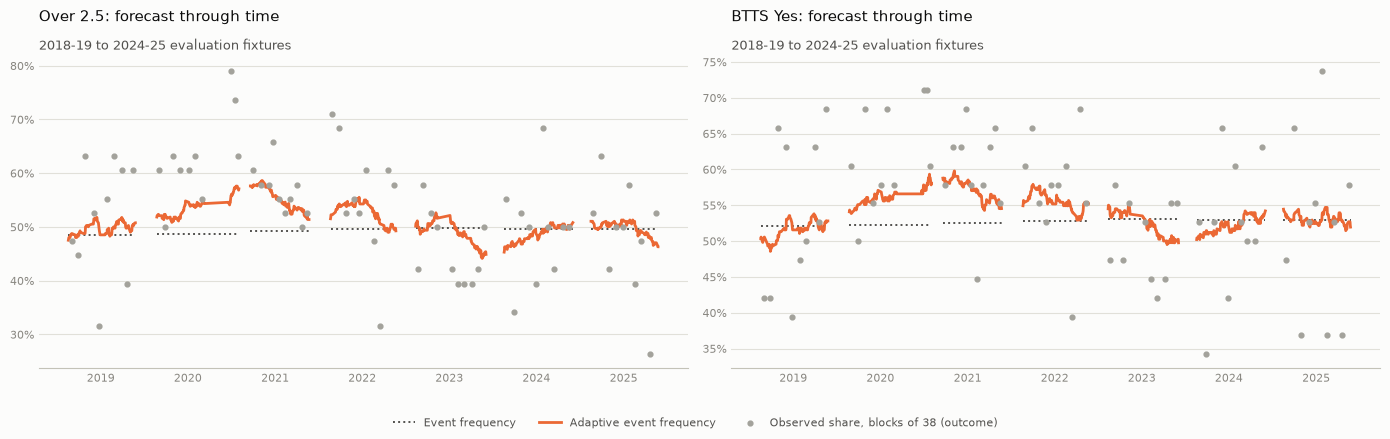

In [9]:
# Figure 66: adaptive probabilities through time, against the static frequency
targets_all = event_targets(predictions)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=False)
fig.patch.set_facecolor(SURFACE)
order = predictions.sort_values(["season", "date", "home_team"], kind="stable")
for ax, event in zip(axes, PRIMARY_EVENTS):
    for method in (FREQUENCY, ADAPTIVE_FREQUENCY):
        daily = order[order["method"] == method].groupby(["season", "date"])[event].mean()
        for season in BACKTEST_SEASONS:
            part = daily.loc[season]
            ax.plot(part.index, part.values, color=COLORS[method], linestyle=STYLE.get(method, "-"),
                    linewidth=2 if method == ADAPTIVE_FREQUENCY else 1.4,
                    label=method if season == BACKTEST_SEASONS[0] else None)
    rows = order[order["method"] == FREQUENCY].copy()
    rows["block"] = rows.groupby("season").cumcount() // 38
    rows["y"] = targets_all.loc[rows.index, event]
    blocks = rows.groupby(["season", "block"]).agg(date=("date", "median"), share=("y", "mean"))
    ax.scatter(blocks["date"], blocks["share"], s=12, color=NEUTRAL, zorder=2,
               label="Observed share, blocks of 38 (outcome)")
    style_axes(ax)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    set_title(ax, f"{EVENTS[event]}: forecast through time", "2018-19 to 2024-25 evaluation fixtures", size=11)
fig.tight_layout(rect=(0, 0.08, 1, 1))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=3, frameon=False, fontsize=8, labelcolor=INK_2)
save_figure(fig, "66_adaptive_probabilities.png")
plt.show()

**Interpretation**

- **The away factor is above 1 in every season** (mean 1.01 to 1.14). The home factor is below 1
  in four of seven seasons (as low as 0.91 in 2024-25). The adaptive Poisson therefore mostly
  shifts goals from the home side to the away side, and adds goals during 2019-22.
- **The adjustments are modest.** Expected total goals change by +0.07 on average (from -0.19 to
  +0.50). The adaptive Over 2.5 probability ranges from 44% to 59% (sd 3 points), compared with a
  static forecast of 48.6% to 49.6%.
- **The adaptive frequency follows the observed blocks but lags them.** In 2019-20 it climbs from
  52% to 57% while the blocks run at 60% or more. In 2022-23 it starts high and comes down during
  the season.

## 3. Pooled and per-season results

Binary log loss and Brier score on identical fixtures; lower is better.

In [10]:
pooled = pooled_metrics(predictions)
ll = pooled[[f"log_loss_{e}" for e in EVENT_NAMES]].rename(columns=lambda c: EVENTS[c.removeprefix("log_loss_")])
br = pooled[[f"brier_{e}" for e in EVENT_NAMES]].rename(columns=lambda c: EVENTS[c.removeprefix("brier_")])
display(ll.style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold")
        .set_caption("Pooled log loss, 2018-19 to 2024-25 (bold = best per event)"))
display(br.style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold").set_caption("Pooled Brier score"))
for event in PRIMARY_EVENTS:
    print(f"Strongest existing model for {EVENTS[event]}: {strongest_existing(predictions, event)}")

,Over 0.5,Over 1.5,Over 2.5,Over 3.5,BTTS Yes
method,,,,,
Event frequency,0.2448,0.5380,0.6947,0.6094,0.6893
League average,0.2427,0.5381,0.6945,0.6099,0.6892
Team attack/defence,0.2449,0.5353,0.6918,0.6089,0.6895
Poisson regression,0.2425,0.5347,0.6912,0.6090,0.6900
Direct logistic,0.2425,0.5372,0.6926,0.6059,0.6877
"Poisson regression, recalibrated",0.2436,0.5355,0.6908,0.6085,0.6890
Adaptive event frequency,0.2434,0.5340,0.6887,0.6066,0.6863
Adaptive Poisson regression,0.2433,0.5322,0.6886,0.6083,0.6865


,Over 0.5,Over 1.5,Over 2.5,Over 3.5,BTTS Yes
method,,,,,
Event frequency,0.0618,0.1763,0.2508,0.2092,0.2481
League average,0.0615,0.1764,0.2507,0.2094,0.2480
Team attack/defence,0.0616,0.1753,0.2491,0.2092,0.2481
Poisson regression,0.0614,0.1751,0.2490,0.2091,0.2484
Direct logistic,0.0616,0.1761,0.2497,0.2077,0.2472
"Poisson regression, recalibrated",0.0615,0.1753,0.2488,0.2089,0.2479
Adaptive event frequency,0.0616,0.1749,0.2478,0.2081,0.2466
Adaptive Poisson regression,0.0615,0.1742,0.2476,0.2089,0.2467


Strongest existing model for Over 2.5: Poisson regression, recalibrated
Strongest existing model for BTTS Yes: Direct logistic


In [11]:
seasonal = season_metrics(predictions)
for event in PRIMARY_EVENTS:
    table = seasonal[f"log_loss_{event}"].unstack("method")[METHODS]
    table.index = table.index.map(season_name)
    display(table.style.format("{:.4f}").highlight_min(axis=1, props="font-weight: bold")
            .set_caption(f"{EVENTS[event]} log loss per season (bold = best)"))
    diff = table.sub(table[FREQUENCY], axis=0).drop(columns=FREQUENCY)
    display(diff.style.format("{:+.4f}").background_gradient(cmap="RdBu", vmin=-0.03, vmax=0.03)
            .set_caption(f"{EVENTS[event]}: log loss minus the static frequency (negative = better)"))

method,Event frequency,League average,Team attack/defence,Poisson regression,Direct logistic,"Poisson regression, recalibrated",Adaptive event frequency,Adaptive Poisson regression
season,,,,,,,,
2018-19,0.6946,0.6943,0.7082,0.6954,0.6891,0.6935,0.6938,0.6966
2019-20,0.7002,0.6991,0.6749,0.6797,0.6831,0.6705,0.6739,0.6638
2020-21,0.6952,0.6951,0.6960,0.6824,0.6850,0.6797,0.6847,0.6842
2021-22,0.6942,0.6939,0.6878,0.6931,0.7094,0.6892,0.6888,0.6891
2022-23,0.6928,0.6929,0.6950,0.6961,0.6923,0.7174,0.6921,0.6948
2023-24,0.6931,0.6931,0.6800,0.6967,0.6943,0.6937,0.6946,0.6970
2024-25,0.6929,0.6930,0.7007,0.6947,0.6952,0.6915,0.6927,0.6950


method,League average,Team attack/defence,Poisson regression,Direct logistic,"Poisson regression, recalibrated",Adaptive event frequency,Adaptive Poisson regression
season,,,,,,,
2018-19,-0.0003,+0.0136,+0.0008,-0.0055,-0.0012,-0.0008,+0.0020
2019-20,-0.0011,-0.0253,-0.0205,-0.0171,-0.0297,-0.0263,-0.0364
2020-21,-0.0001,+0.0008,-0.0128,-0.0102,-0.0155,-0.0104,-0.0110
2021-22,-0.0003,-0.0064,-0.0011,+0.0152,-0.0050,-0.0054,-0.0052
2022-23,+0.0002,+0.0022,+0.0033,-0.0005,+0.0247,-0.0007,+0.0020
2023-24,+0.0000,-0.0130,+0.0037,+0.0013,+0.0007,+0.0015,+0.0040
2024-25,+0.0001,+0.0078,+0.0018,+0.0023,-0.0014,-0.0002,+0.0021


method,Event frequency,League average,Team attack/defence,Poisson regression,Direct logistic,"Poisson regression, recalibrated",Adaptive event frequency,Adaptive Poisson regression
season,,,,,,,,
2018-19,0.6911,0.6911,0.7004,0.6880,0.6904,0.6889,0.6909,0.6869
2019-20,0.6835,0.6831,0.6706,0.6812,0.6710,0.6731,0.6697,0.6709
2020-21,0.6844,0.6842,0.6787,0.6903,0.6836,0.6817,0.6771,0.6824
2021-22,0.6863,0.6860,0.6769,0.6795,0.6802,0.6763,0.6834,0.6756
2022-23,0.6947,0.6949,0.7020,0.7007,0.6978,0.7146,0.6957,0.7006
2023-24,0.6921,0.6922,0.6949,0.6928,0.6903,0.6936,0.6927,0.6943
2024-25,0.6930,0.6932,0.7031,0.6973,0.7003,0.6945,0.6946,0.6950


method,League average,Team attack/defence,Poisson regression,Direct logistic,"Poisson regression, recalibrated",Adaptive event frequency,Adaptive Poisson regression
season,,,,,,,
2018-19,-0.0000,+0.0092,-0.0032,-0.0007,-0.0022,-0.0002,-0.0042
2019-20,-0.0004,-0.0130,-0.0023,-0.0126,-0.0104,-0.0138,-0.0126
2020-21,-0.0002,-0.0057,+0.0059,-0.0008,-0.0027,-0.0073,-0.0020
2021-22,-0.0003,-0.0094,-0.0068,-0.0061,-0.0101,-0.0030,-0.0107
2022-23,+0.0002,+0.0073,+0.0060,+0.0031,+0.0199,+0.0010,+0.0059
2023-24,+0.0001,+0.0028,+0.0007,-0.0018,+0.0015,+0.0007,+0.0022
2024-25,+0.0002,+0.0101,+0.0043,+0.0073,+0.0015,+0.0016,+0.0020


In [12]:
# Context only: the betting market's Over/Under 2.5 on the same fixtures (never an input)
odds = market_over_under(seasons=set(BACKTEST_SEASONS)).dropna(subset=["market_over_2_5"])
rows = predictions[["season", "method", "date", "home_team", "away_team", "home_goals", "away_goals", "over_2_5"]]
rows = rows.merge(odds[["date", "home_team", "away_team", "market_over_2_5"]], on=["date", "home_team", "away_team"])
y = (rows["home_goals"] + rows["away_goals"] > 2.5).astype(float)
def ll_of(p): return -(y * np.log(p) + (1 - y) * np.log(1 - p))
market_table = pd.DataFrame({m: [ll_of(rows["over_2_5"]).where(rows["method"] == m).mean(),
                                 int((rows["method"] == m).sum())] for m in METHODS}, index=["log_loss", "fixtures"]).T
market_table.loc[MARKET] = [ll_of(rows.loc[rows["method"] == FREQUENCY, "market_over_2_5"]).mean(),
                            int((rows["method"] == FREQUENCY).sum())]
display(market_table.style.format({"log_loss": "{:.4f}", "fixtures": "{:,.0f}"})
        .set_caption("Over 2.5 log loss on the fixtures with market odds (context, not part of the rule)"))

,log_loss,fixtures
Event frequency,0.6947,"2,658"
League average,0.6945,"2,658"
Team attack/defence,0.6918,"2,658"
Poisson regression,0.6912,"2,658"
Direct logistic,0.6927,"2,658"
"Poisson regression, recalibrated",0.6908,"2,658"
Adaptive event frequency,0.6886,"2,658"
Adaptive Poisson regression,0.6886,"2,658"
Market average (O/U 2.5),0.6786,"2,658"


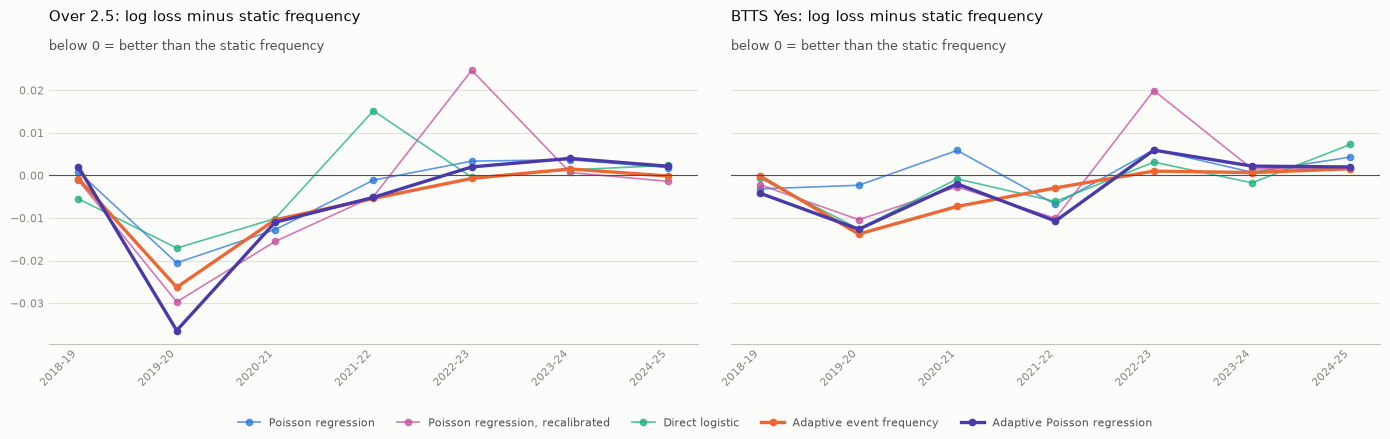

In [13]:
# Figure 67: per-season log loss minus the static frequency
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
fig.patch.set_facecolor(SURFACE)
x = np.arange(len(BACKTEST_SEASONS))
for ax, event in zip(axes, PRIMARY_EVENTS):
    table = seasonal[f"log_loss_{event}"].unstack("method")
    for method in [MODEL, RECALIBRATED, DIRECT, ADAPTIVE_FREQUENCY, ADAPTIVE_POISSON]:
        diff = (table[method] - table[FREQUENCY]).to_numpy()
        ax.plot(x, diff, marker="o", markersize=4.5, linewidth=2.4 if method in CANDIDATES else 1.2,
                alpha=1 if method in CANDIDATES else 0.75, color=COLORS[method], label=method)
    ax.axhline(0, color=INK_2, linewidth=0.8)
    style_axes(ax)
    season_axis(ax)
    set_title(ax, f"{EVENTS[event]}: log loss minus static frequency", "below 0 = better than the static frequency",
              size=11)
fig.tight_layout(rect=(0, 0.07, 1, 1))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=5, frameon=False, fontsize=8, labelcolor=INK_2)
save_figure(fig, "67_drift_log_loss_by_season.png")
plt.show()

**Interpretation**

- **Both adaptive candidates have the lowest pooled log loss on both primary events:**
  - Over 2.5: adaptive Poisson 0.6886 and adaptive frequency 0.6887, against 0.6947 for the static
    frequency and 0.6908 for the strongest existing model (the recalibrated Poisson);
  - BTTS: adaptive frequency 0.6863 and adaptive Poisson 0.6865, against 0.6893 static and 0.6877
    for the strongest existing model (the direct logistic).

  The adaptive Poisson is also best on Over 1.5 (0.5322). On Over 3.5 the direct logistic stays
  ahead (0.6059 vs 0.6066), and on Over 0.5 nothing beats the Poisson regression (0.2425).
- **The gains come from the drift seasons.** On Over 2.5 most of the gain is in 2019-20 (-0.026
  for the adaptive frequency, -0.036 for the adaptive Poisson), with smaller gains in 2020-21 and
  2021-22.
- **From 2022-23 to 2024-25 the picture splits:**
  - the adaptive frequency is within 0.002 of the static frequency;
  - the adaptive Poisson is slightly worse than static (+0.002 to +0.004), because it inherits the
    Poisson regression's weaker years.
- **Unlike the recalibration, adaptation does not blow up when scoring falls.** In 2022-23 the
  recalibrated Poisson lost 0.025 on Over 2.5. The adaptive frequency gained 0.0007 that season,
  because its window had already come down.
- **Still far from the market:** on the 2,658 fixtures with odds, the market scores 0.6786 on
  Over 2.5, against 0.6886 for the best adaptive method.

## 4. Calibration

* **Mean vs observed:** is the average probability right?
* **Calibration slope and intercept:** logistic regression of the outcome on `logit(p)`; slope 1 is
  ideal, **below 1 = too extreme, above 1 = too timid** (the probabilities move less than the
  outcomes do). Not estimated for forecasts that barely vary (static frequency, league average).
* **Reliability bins:** 10 equal-count bins, each with a 95% Wilson interval.

In [14]:
calibration = calibration_table(predictions)
for event in PRIMARY_EVENTS:
    view = calibration[calibration["event"] == event].set_index("method")[
        ["mean_predicted", "observed", "difference", "calibration_intercept", "calibration_slope", "ece", "bins_outside"]]
    display(view.style.format({"mean_predicted": "{:.1%}", "observed": "{:.1%}", "difference": "{:+.1%}",
                               "calibration_intercept": "{:+.3f}", "calibration_slope": "{:.2f}", "ece": "{:.1%}",
                               "bins_outside": "{:.0f}"}, na_rep="-")
            .set_caption(f"{EVENTS[event]}: calibration (bins_outside of 10)"))
others = calibration.pivot(index="method", columns="label", values="calibration_slope").reindex(METHODS)
display(others.style.format("{:.2f}", na_rep="-").set_caption("Calibration slope, every event"))

,mean_predicted,observed,difference,calibration_intercept,calibration_slope,ece,bins_outside
method,,,,,,,
Event frequency,49.3%,52.9%,-3.6%,-,-,5.9%,5
League average,49.4%,52.9%,-3.4%,-,-,5.9%,5
Team attack/defence,52.5%,52.9%,-0.4%,+0.065,0.49,4.5%,5
Poisson regression,51.8%,52.9%,-1.1%,+0.077,0.53,4.6%,3
Direct logistic,51.2%,52.9%,-1.6%,+0.092,0.45,3.7%,3
"Poisson regression, recalibrated",54.3%,52.9%,+1.4%,+0.009,0.61,3.6%,1
Adaptive event frequency,51.2%,52.9%,-1.6%,+0.044,1.44,2.9%,0
Adaptive Poisson regression,53.4%,52.9%,+0.5%,+0.028,0.63,2.9%,1


,mean_predicted,observed,difference,calibration_intercept,calibration_slope,ece,bins_outside
method,,,,,,,
Event frequency,52.7%,55.3%,-2.6%,-,-,4.5%,3
League average,52.8%,55.3%,-2.4%,-,-,4.5%,3
Team attack/defence,52.5%,55.3%,-2.8%,+0.163,0.48,3.9%,2
Poisson regression,51.5%,55.3%,-3.8%,+0.177,0.58,3.8%,1
Direct logistic,53.9%,55.3%,-1.3%,+0.124,0.55,2.7%,2
"Poisson regression, recalibrated",55.7%,55.3%,+0.4%,+0.148,0.27,2.6%,1
Adaptive event frequency,54.0%,55.3%,-1.3%,+0.021,1.20,2.0%,0
Adaptive Poisson regression,53.0%,55.3%,-2.3%,+0.125,0.73,2.8%,1


label,BTTS Yes,Over 0.5,Over 1.5,Over 2.5,Over 3.5
method,,,,,
Event frequency,-,-,-,-,-
League average,-,-,-,-,-
Team attack/defence,0.48,0.31,0.51,0.49,0.49
Poisson regression,0.58,0.52,0.62,0.53,0.46
Direct logistic,0.55,0.65,0.38,0.45,0.72
"Poisson regression, recalibrated",0.27,0.19,0.47,0.61,0.48
Adaptive event frequency,1.20,0.34,1.22,1.44,1.08
Adaptive Poisson regression,0.73,0.41,0.70,0.63,0.53


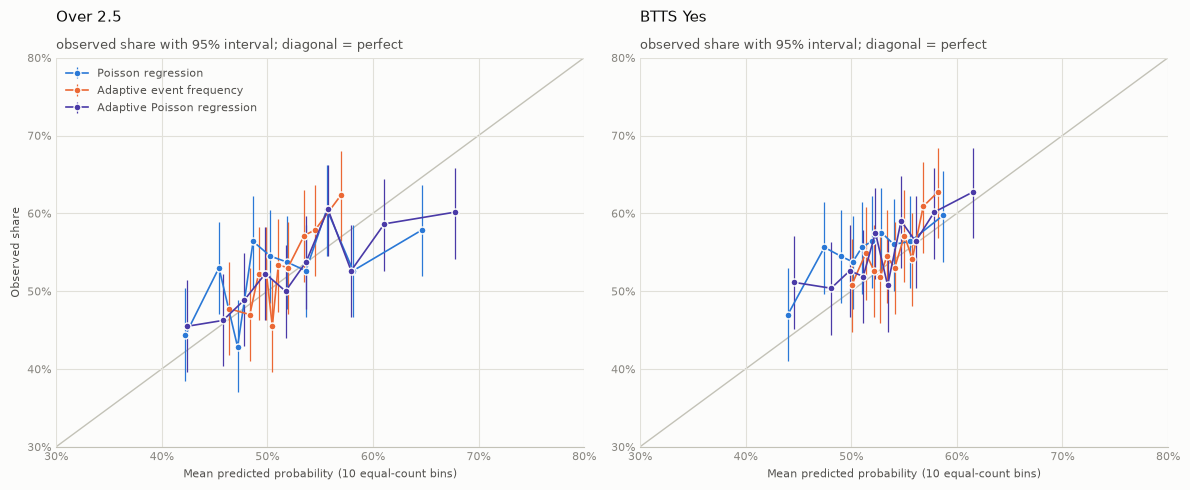

In [15]:
# Figure 68: reliability diagrams for Over 2.5 and BTTS
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(SURFACE)
for ax, event in zip(axes, PRIMARY_EVENTS):
    for method in (MODEL, ADAPTIVE_FREQUENCY, ADAPTIVE_POISSON):
        mask = predictions["method"] == method
        table = reliability_table(predictions.loc[mask, event], targets_all.loc[mask, event])
        ax.errorbar(table["mean_predicted"], table["observed"],
                    yerr=[table["observed"] - table["ci_low"], table["ci_high"] - table["observed"]],
                    fmt="o-", color=COLORS[method], markersize=5, linewidth=1.2, elinewidth=0.9, capsize=0,
                    markeredgecolor=SURFACE, markeredgewidth=1, label=method)
    ax.plot([0.3, 0.8], [0.3, 0.8], color=BASELINE_LINE, linewidth=1, zorder=0)
    style_axes(ax, grid="both")
    ax.set_xlim(0.3, 0.8)
    ax.set_ylim(0.3, 0.8)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Mean predicted probability (10 equal-count bins)", fontsize=8, color=INK_2)
    set_title(ax, EVENTS[event], "observed share with 95% interval; diagonal = perfect", size=11)
axes[0].set_ylabel("Observed share", fontsize=8, color=INK_2)
legend(axes[0], loc="upper left")
fig.tight_layout()
save_figure(fig, "68_drift_reliability.png")
plt.show()

**Interpretation**

- **The adaptive frequency is too timid, not too extreme.**
  - Its calibration slope is 1.44 for Over 2.5 and 1.20 for BTTS: its probabilities move in the
    right direction but by less than the outcomes justify, consistent with 50% shrinkage and a lag.
  - Its means are 1.6 (Over 2.5) and 1.3 (BTTS) points too low, and none of its reliability bins
    falls outside its interval.
  - For BTTS it meets every calibration criterion (slope 1.195, just inside 1.2); for Over 2.5
    the slope fails.
- **The adaptive Poisson is less extreme than the Poisson regression but still too extreme.**
  - Slopes are 0.63 and 0.73, against 0.53 and 0.58 for the Poisson regression.
  - The Over 2.5 mean is now right (+0.5 points).
  - BTTS is still 2.3 points too low: the level shift fixes total goals better than the BTTS
    shortfall.
- **Season-level bias shrinks.** The average absolute season bias falls:
  - Over 2.5: from 5.3 points (static) and 3.7 (Poisson regression) to 3.0 for both adaptive
    methods;
  - BTTS: from 3.9 and 4.1 to 2.3 and 2.5.

  So the adjustments remove real drift error, not just add movement.

## 5. Drift diagnostics

### 5a. Do scoring changes precede or follow the model errors?

Each season's fixtures are cut into 10 chronological blocks of 38. For each block: the Poisson
regression's mean error in total goals (observed minus expected) and the mean adjustment the
adaptive level applied, which was fixed before every fixture was played. If errors persist from
block to block, a past-only statistic can anticipate part of the next error.

In [16]:
blocks = block_errors(drift)
summary = blocks.groupby("season")[["error", "adjustment", "adjusted_error"]].mean()
summary.index = summary.index.map(season_name)
display(summary.style.format("{:+.3f}").set_caption(
    "Mean error in total goals per match: Poisson regression, the adjustment, and what is left after it"))
persistence = error_persistence(blocks, max_lag=5)
display(persistence.style.format("{:+.2f}", na_rep="-").hide(axis="index").set_caption(
    "Correlation of a block's Poisson error with earlier errors, and with adjustments k blocks earlier or later"))
spread = blocks[["error", "adjustment", "adjusted_error"]].std()
print(f"Block-to-block sd: error {spread['error']:.3f}, adjustment {spread['adjustment']:.3f}, "
      f"error after adjustment {spread['adjusted_error']:.3f} goals per match")

,error,adjustment,adjusted_error
season,,,
2018-19,-0.058,+0.021,-0.079
2019-20,+0.320,+0.145,+0.175
2020-21,+0.181,+0.242,-0.061
2021-22,+0.018,+0.171,-0.153
2022-23,-0.171,-0.040,-0.130
2023-24,-0.068,-0.028,-0.040
2024-25,-0.154,-0.008,-0.147


lag_blocks,error_vs_earlier_error,error_vs_earlier_adjustment,error_vs_later_adjustment
+0.00,-,+0.41,+0.41
+1.00,+0.19,+0.28,+0.58
+2.00,+0.17,+0.25,+0.56
+3.00,+0.32,+0.22,+0.53
+4.00,+0.10,+0.15,+0.56
+5.00,+0.15,+0.13,+0.53


Block-to-block sd: error 0.344, adjustment 0.122, error after adjustment 0.314 goals per match


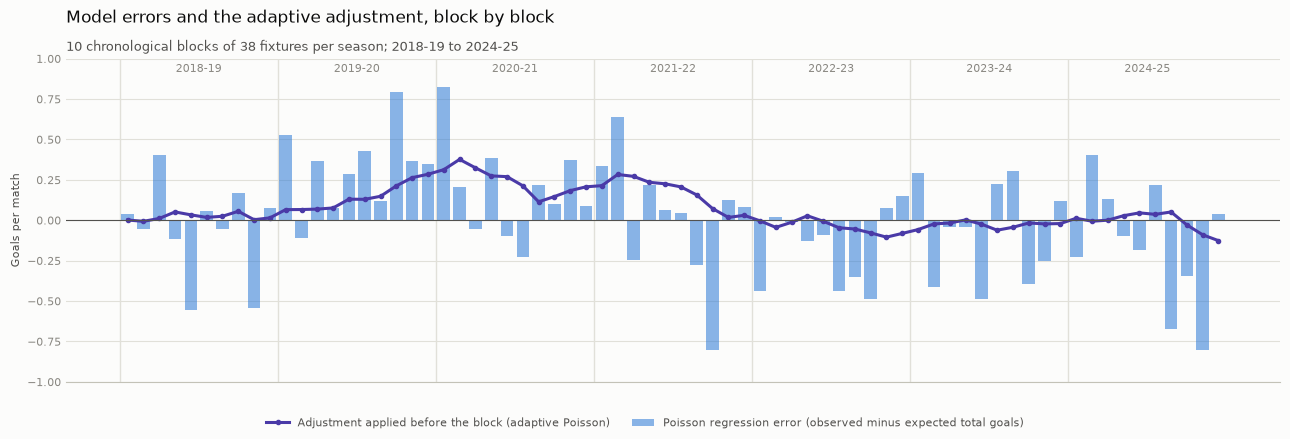

In [17]:
# Figure 69: block errors and the adjustment over time
fig, ax = plt.subplots(figsize=(13, 4.4))
fig.patch.set_facecolor(SURFACE)
blocks_sorted = blocks.sort_values(["season", "block"]).reset_index(drop=True)
x = np.arange(len(blocks_sorted))
ax.bar(x, blocks_sorted["error"], width=0.8, color=COLORS[MODEL], alpha=0.55,
       label="Poisson regression error (observed minus expected total goals)")
ax.plot(x, blocks_sorted["adjustment"], color=COLORS[ADAPTIVE_POISSON], linewidth=2.2, marker="o", markersize=3,
        label="Adjustment applied before the block (adaptive Poisson)")
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_ylim(-1.0, 1.0)
for k, season in enumerate(BACKTEST_SEASONS):
    ax.axvline(k * 10 - 0.5, color=GRID, linewidth=1, zorder=0)
    ax.text(k * 10 + 4.5, 0.97, SEASON_LABELS[season], fontsize=8, color=MUTED, ha="center", va="top")
style_axes(ax)
ax.set_xticks([])
ax.set_ylabel("Goals per match", fontsize=8, color=INK_2)
set_title(ax, "Model errors and the adaptive adjustment, block by block",
          "10 chronological blocks of 38 fixtures per season; 2018-19 to 2024-25")
fig.tight_layout(rect=(0, 0.07, 1, 1))
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=2, frameon=False, fontsize=8, labelcolor=INK_2)
save_figure(fig, "69_errors_and_adjustment.png")
plt.show()

### 5b. Better calibration, or just noise?

The season-level bias (mean predicted minus observed share) shows whether the adaptive methods
remove the drift error or only move the forecasts around.

In [18]:
bias = season_bias(predictions, [FREQUENCY, MODEL, RECALIBRATED, ADAPTIVE_FREQUENCY, ADAPTIVE_POISSON])
view = bias.rename(index=lambda s: season_name(s) if isinstance(s, (int, np.integer)) else EVENTS.get(s, s))
display(view.style.format("{:+.1%}").background_gradient(cmap="RdBu_r", vmin=-0.12, vmax=0.12)
        .set_caption("Mean predicted minus observed share, per season (positive = too high)"))
size = bias.abs().groupby(level="event").mean()
size.index = size.index.map(EVENTS)
display(size.style.format("{:.1%}").set_caption("Average absolute season bias"))

method,Event frequency,Poisson regression,"Poisson regression, recalibrated",Adaptive event frequency,Adaptive Poisson regression
event,,,,,
BTTS Yes,3.9%,4.1%,3.8%,2.3%,2.5%
Over 2.5,5.3%,3.7%,4.1%,3.0%,3.0%


### 5c. Early versus late season

Each season's fixtures are split into the first and second half by date. Early in a season the
window still mostly holds the previous season's matches; late in the season it is mostly the
current season's.

In [19]:
phases = phase_table(predictions)
rows = []
for metric in ["log_loss_over_2_5", "log_loss_btts_yes"]:
    table = phases[metric]
    for comparator in (FREQUENCY, MODEL):
        diff = table.sub(table.loc[comparator], axis=1).loc[CANDIDATES + [RECALIBRATED, DIRECT]]
        diff.columns = ["first half", "second half"]
        rows.append(diff.assign(event=EVENTS[metric.removeprefix("log_loss_")], vs=comparator))
phase_view = pd.concat(rows).reset_index().set_index(["event", "vs", "method"])
display(phase_view.style.format("{:+.4f}").set_caption("Log loss minus the comparator, by half of the season"))
raw_phase = phases.copy()
raw_phase.columns = [f"{EVENTS[m.removeprefix('log_loss_')]}, {'first' if p == 0 else 'second'} half"
                     for m, p in raw_phase.columns]
display(raw_phase.loc[METHODS].style.format("{:.4f}").set_caption("Mean log loss by half of the season"))

,"Over 2.5, first half","Over 2.5, second half","BTTS Yes, first half","BTTS Yes, second half"
method,,,,
Event frequency,0.6944,0.6950,0.6898,0.6889
League average,0.6942,0.6948,0.6897,0.6887
Team attack/defence,0.6914,0.6922,0.6888,0.6902
Poisson regression,0.6915,0.6908,0.6899,0.6900
Direct logistic,0.6918,0.6935,0.6882,0.6871
"Poisson regression, recalibrated",0.6885,0.6930,0.6874,0.6905
Adaptive event frequency,0.6891,0.6883,0.6864,0.6862
Adaptive Poisson regression,0.6886,0.6886,0.6858,0.6872


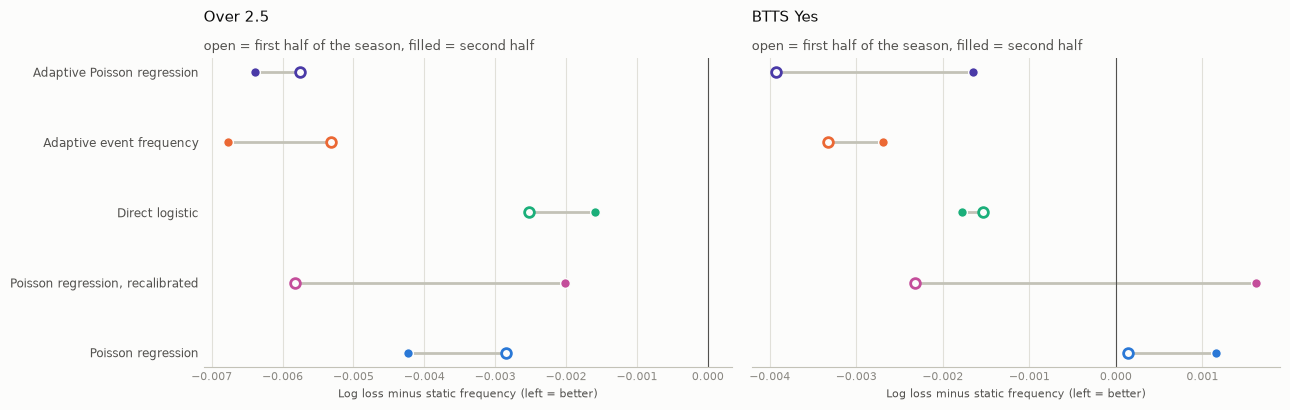

In [20]:
# Figure 70: early vs late season gains over the static frequency
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
fig.patch.set_facecolor(SURFACE)
shown = [MODEL, RECALIBRATED, DIRECT, ADAPTIVE_FREQUENCY, ADAPTIVE_POISSON]
for ax, metric in zip(axes, ["log_loss_over_2_5", "log_loss_btts_yes"]):
    table = phases[metric]
    diff = table.sub(table.loc[FREQUENCY], axis=1)
    y = np.arange(len(shown))
    for k, method in enumerate(shown):
        first, second = diff.loc[method, 0], diff.loc[method, 1]
        ax.plot([first, second], [k, k], color=BASELINE_LINE, linewidth=2, zorder=1)
        ax.plot(first, k, "o", color=COLORS[method], markersize=7, markerfacecolor=SURFACE, markeredgewidth=2,
                label="first half" if k == 0 else None, zorder=2)
        ax.plot(second, k, "o", color=COLORS[method], markersize=7, markeredgecolor=SURFACE,
                label="second half" if k == 0 else None, zorder=3)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    style_axes(ax, grid="x")
    ax.set_yticks(y)
    ax.set_yticklabels(shown, fontsize=8.5, color=INK_2)
    ax.invert_yaxis()
    ax.set_xlabel("Log loss minus static frequency (left = better)", fontsize=8, color=INK_2)
    set_title(ax, EVENTS[metric.removeprefix("log_loss_")], "open = first half of the season, filled = second half",
              size=11)
fig.tight_layout()
save_figure(fig, "70_early_late_season.png")
plt.show()

**Interpretation**

- **Errors persist, but weakly.**
  - A block's Poisson error correlates 0.10 to 0.32 with the errors one to five blocks earlier.
    That is enough for a past-only statistic to help a little, but far from predictable.
  - The adjustment fixed before each fixture correlates 0.41 with the block's error, so it points
    the right way.
- **The statistic follows the errors more than it anticipates them.** The error correlates more
  with *later* adjustments (0.53 to 0.59) than with earlier ones (0.13 to 0.28). Figure 69 shows
  the lag:
  - 2019-20: the error averaged +0.32 goals, but the adjustment only +0.15;
  - 2021-22: the adjustment was still +0.17 when the error had almost vanished (+0.02), so it
    overshot;
  - 2022-23: scoring fell (-0.17), but the adjustment was only -0.04.
- **Signal versus noise:** the block-to-block spread of the error falls from 0.34 to 0.31 goals
  after adjustment, a small real reduction rather than added noise.
- **Most of the gain is already there early in the season:**
  - Over 2.5: the adaptive frequency gains 0.0053 on the static frequency in the first half and
    0.0068 in the second; the adaptive Poisson 0.0058 and 0.0064.
  - BTTS: the adaptive Poisson's gain is larger early (0.0039 vs 0.0017).

  Early in a season the window holds mostly last season's matches. So much of the benefit comes
  from using *recent seasons* instead of the 1993-onward average, not from updating within the
  season.
- The recalibrated Poisson's gains, by contrast, are concentrated early in the season (Over 2.5
  0.0058 early, 0.0020 late; BTTS turns worse than static late).

## 6. Statistical uncertainty

Paired bootstrap of per-match log-loss differences on identical fixtures (10,000 resamples).

* **Decision family (8):** each candidate against the static frequency and the strongest existing
  model, Over 2.5 and BTTS, with Bonferroni-adjusted intervals (confidence 1 - 0.05/8) and Holm
  p-values.
* **Primary metrics against every existing method (24)** and **secondary metrics (32)**, each
  corrected within its own family. Exploratory.
* **Season level:** seasons won, sign test and leave-one-season-out range.

In [21]:
family = rule_comparisons(predictions, n_resamples=N_RESAMPLES)
fmt = {c: "{:+.4f}" for c in ["difference", "ci_low", "ci_high", "adj_ci_low", "adj_ci_high"]} | {"p_holm": "{:.3f}"}
display(family[["a", "b", "label", "difference", "ci_low", "ci_high", "adj_ci_low", "adj_ci_high", "p_holm",
                "adjusted_interval_excludes_zero"]].style.format(fmt).hide(axis="index")
        .set_caption(f"Decision family ({RULE_COMPARISONS}): candidate minus comparator (negative = candidate better)"))
primary = primary_comparisons(predictions, n_resamples=N_RESAMPLES)
display(primary[["a", "b", "label", "difference", "ci_low", "ci_high", "adj_ci_low", "adj_ci_high", "p_holm",
                 "adjusted_interval_excludes_zero"]].style.format(fmt).hide(axis="index")
        .set_caption(f"Primary metrics against every existing method ({len(primary)}, Bonferroni within this family)"))
secondary = secondary_comparisons(predictions, n_resamples=N_RESAMPLES)
display(secondary[["a", "b", "label", "difference", "ci_low", "ci_high", "adj_ci_low", "adj_ci_high", "p_holm",
                   "adjusted_interval_excludes_zero"]].style.format(fmt).hide(axis="index")
        .set_caption(f"Secondary comparisons ({len(secondary)}, Bonferroni within this family)"))

a,b,label,difference,ci_low,ci_high,adj_ci_low,adj_ci_high,p_holm,adjusted_interval_excludes_zero
Adaptive event frequency,Event frequency,"Log loss, Over 2.5",-0.0060,-0.0088,-0.0033,-0.0099,-0.0023,0.001,True
Adaptive event frequency,"Poisson regression, recalibrated","Log loss, Over 2.5",-0.0021,-0.0065,+0.0025,-0.0083,+0.0041,1.000,False
Adaptive event frequency,Event frequency,"Log loss, BTTS Yes",-0.0030,-0.0051,-0.0009,-0.0060,+0.0001,0.048,False
Adaptive event frequency,Direct logistic,"Log loss, BTTS Yes",-0.0014,-0.0043,+0.0016,-0.0054,+0.0027,1.000,False
Adaptive Poisson regression,Event frequency,"Log loss, Over 2.5",-0.0061,-0.0126,+0.0004,-0.0152,+0.0029,0.412,False
Adaptive Poisson regression,"Poisson regression, recalibrated","Log loss, Over 2.5",-0.0021,-0.0055,+0.0012,-0.0069,+0.0025,0.854,False
Adaptive Poisson regression,Event frequency,"Log loss, BTTS Yes",-0.0028,-0.0065,+0.0009,-0.0080,+0.0021,0.710,False
Adaptive Poisson regression,Direct logistic,"Log loss, BTTS Yes",-0.0011,-0.0042,+0.0019,-0.0052,+0.0031,1.000,False


a,b,label,difference,ci_low,ci_high,adj_ci_low,adj_ci_high,p_holm,adjusted_interval_excludes_zero
Adaptive event frequency,Event frequency,"Log loss, Over 2.5",-0.0060,-0.0088,-0.0033,-0.0103,-0.0018,0.002,True
Adaptive event frequency,League average,"Log loss, Over 2.5",-0.0058,-0.0085,-0.0031,-0.0100,-0.0017,0.002,True
Adaptive event frequency,Team attack/defence,"Log loss, Over 2.5",-0.0031,-0.0103,+0.0039,-0.0143,+0.0078,1.000,False
Adaptive event frequency,Poisson regression,"Log loss, Over 2.5",-0.0025,-0.0076,+0.0027,-0.0105,+0.0058,1.000,False
Adaptive event frequency,Direct logistic,"Log loss, Over 2.5",-0.0040,-0.0085,+0.0006,-0.0112,+0.0031,1.000,False
Adaptive event frequency,"Poisson regression, recalibrated","Log loss, Over 2.5",-0.0021,-0.0065,+0.0025,-0.0092,+0.0049,1.000,False
Adaptive event frequency,Event frequency,"Log loss, BTTS Yes",-0.0030,-0.0051,-0.0009,-0.0064,+0.0004,0.143,False
Adaptive event frequency,League average,"Log loss, BTTS Yes",-0.0029,-0.0050,-0.0008,-0.0063,+0.0005,0.148,False
Adaptive event frequency,Team attack/defence,"Log loss, BTTS Yes",-0.0032,-0.0086,+0.0023,-0.0118,+0.0048,1.000,False
Adaptive event frequency,Poisson regression,"Log loss, BTTS Yes",-0.0037,-0.0076,+0.0001,-0.0098,+0.0025,1.000,False


a,b,label,difference,ci_low,ci_high,adj_ci_low,adj_ci_high,p_holm,adjusted_interval_excludes_zero
Adaptive event frequency,Event frequency,"Log loss, Over 0.5",-0.0014,-0.0030,+0.0003,-0.0040,+0.0014,1.000,False
Adaptive event frequency,Event frequency,"Log loss, Over 1.5",-0.0041,-0.0063,-0.0018,-0.0078,-0.0003,0.006,True
Adaptive event frequency,Event frequency,"Log loss, Over 3.5",-0.0028,-0.0052,-0.0004,-0.0066,+0.0011,0.470,False
Adaptive event frequency,Event frequency,"Brier, Over 0.5",-0.0002,-0.0004,+0.0000,-0.0006,+0.0002,1.000,False
Adaptive event frequency,Event frequency,"Brier, Over 1.5",-0.0014,-0.0022,-0.0007,-0.0028,-0.0001,0.006,True
Adaptive event frequency,Event frequency,"Brier, Over 2.5",-0.0030,-0.0044,-0.0016,-0.0052,-0.0009,0.003,True
Adaptive event frequency,Event frequency,"Brier, Over 3.5",-0.0012,-0.0022,-0.0002,-0.0027,+0.0004,0.470,False
Adaptive event frequency,Event frequency,"Brier, BTTS Yes",-0.0015,-0.0026,-0.0004,-0.0032,+0.0002,0.190,False
Adaptive event frequency,Poisson regression,"Log loss, Over 0.5",+0.0009,-0.0022,+0.0039,-0.0044,+0.0056,1.000,False
Adaptive event frequency,Poisson regression,"Log loss, Over 1.5",-0.0007,-0.0049,+0.0035,-0.0075,+0.0059,1.000,False


In [22]:
pairs = ([(c, FREQUENCY) for c in CANDIDATES] + [(c, MODEL) for c in CANDIDATES]
         + [(c, strongest_existing(predictions, e)) for c in CANDIDATES for e in PRIMARY_EVENTS])
sensitivity = season_sensitivity(predictions, list(dict.fromkeys(pairs)))
display(sensitivity.style.format({"sign_test_p": "{:.3f}", "pooled_difference": "{:+.4f}",
                                  "worst_season_difference": "{:+.4f}", "leave_one_out_min": "{:+.4f}",
                                  "leave_one_out_max": "{:+.4f}"}).hide(axis="index")
        .set_caption("Season-level consistency (negative = a better)"))

a,b,metric,label,seasons,seasons_better,sign_test_p,pooled_difference,worst_season_difference,leave_one_out_min,leave_one_out_max
Adaptive event frequency,Event frequency,log_loss_over_2_5,"Log loss, Over 2.5",7,6,0.125,-0.0060,+0.0015,-0.0073,-0.0027
Adaptive event frequency,Event frequency,log_loss_btts_yes,"Log loss, BTTS Yes",7,4,1.000,-0.0030,+0.0016,-0.0038,-0.0012
Adaptive Poisson regression,Event frequency,log_loss_over_2_5,"Log loss, Over 2.5",7,3,1.000,-0.0061,+0.0040,-0.0078,-0.0010
Adaptive Poisson regression,Event frequency,log_loss_btts_yes,"Log loss, BTTS Yes",7,4,1.000,-0.0028,+0.0059,-0.0042,-0.0011
Adaptive event frequency,Poisson regression,log_loss_over_2_5,"Log loss, Over 2.5",7,6,0.125,-0.0025,+0.0023,-0.0033,-0.0020
Adaptive event frequency,Poisson regression,log_loss_btts_yes,"Log loss, BTTS Yes",7,5,0.453,-0.0037,+0.0039,-0.0049,-0.0021
Adaptive Poisson regression,Poisson regression,log_loss_over_2_5,"Log loss, Over 2.5",7,3,1.000,-0.0025,+0.0017,-0.0032,-0.0003
Adaptive Poisson regression,Poisson regression,log_loss_btts_yes,"Log loss, BTTS Yes",7,6,0.125,-0.0034,+0.0014,-0.0043,-0.0023
Adaptive event frequency,"Poisson regression, recalibrated",log_loss_over_2_5,"Log loss, Over 2.5",7,2,0.453,-0.0021,+0.0051,-0.0033,+0.0018
Adaptive event frequency,"Poisson regression, recalibrated",log_loss_btts_yes,"Log loss, BTTS Yes",7,4,1.000,-0.0027,+0.0071,-0.0043,+0.0000


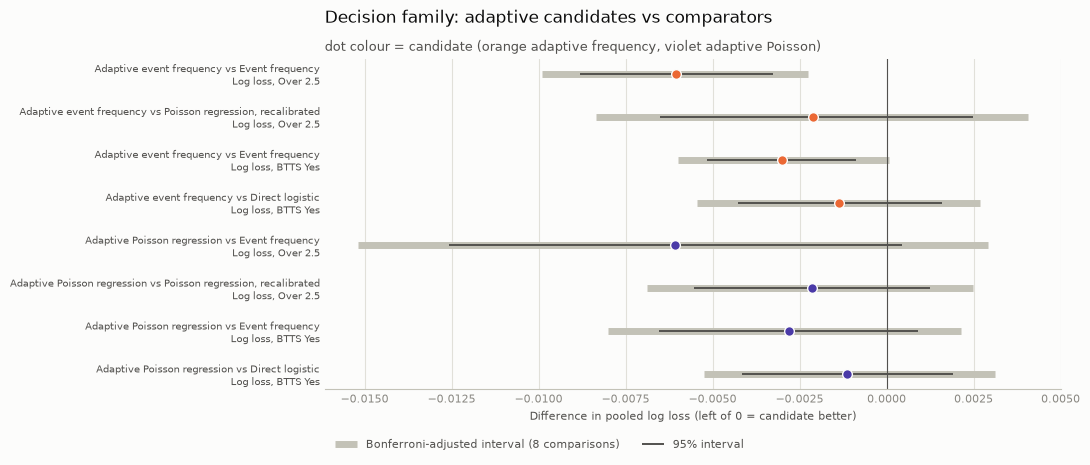

In [23]:
# Figure 71: forest plot of the decision family
fig, ax = plt.subplots(figsize=(11, 4.8))
fig.patch.set_facecolor(SURFACE)
labels = [f"{r.a} vs {r.b}\n{r.label}" for r in family.itertuples()]
y = np.arange(len(family))
ax.hlines(y, family["adj_ci_low"], family["adj_ci_high"], color=BASELINE_LINE, linewidth=5,
          label=f"Bonferroni-adjusted interval ({RULE_COMPARISONS} comparisons)")
ax.hlines(y, family["ci_low"], family["ci_high"], color=INK_2, linewidth=1.4, label="95% interval")
for k, row in enumerate(family.itertuples()):
    ax.plot(row.difference, k, "o", color=COLORS[row.a], markersize=7, markeredgecolor=SURFACE)
ax.axvline(0, color=INK_2, linewidth=0.8)
style_axes(ax, grid="x")
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=7.5, color=INK_2)
ax.invert_yaxis()
ax.set_xlabel("Difference in pooled log loss (left of 0 = candidate better)", fontsize=8, color=INK_2)
set_title(ax, "Decision family: adaptive candidates vs comparators",
          "dot colour = candidate (orange adaptive frequency, violet adaptive Poisson)")
legend(ax, loc="upper left", bbox_to_anchor=(0, -0.12), ncols=2)
fig.tight_layout()
save_figure(fig, "71_drift_decision_intervals.png")
plt.show()

**Interpretation**

- **One comparison in the decision family clears the adjusted bar:** adaptive frequency vs static
  frequency on Over 2.5, -0.0060 with a Bonferroni-adjusted interval of -0.0099 to -0.0023 (Holm
  p 0.001). It also wins 6 of 7 seasons and stays below 0 whichever season is left out (largest
  leave-one-out value -0.0027).
- **BTTS falls just short:** adaptive frequency vs static is -0.0030, with an adjusted interval of
  -0.0060 to +0.0001. It wins only 4 of 7 seasons.
- **The adaptive Poisson is noisier.** Its Over 2.5 gain (-0.0061) is as large but rests on
  2019-20 (3 of 7 seasons, adjusted interval -0.0152 to +0.0029).
- **No candidate is shown to beat the strongest existing model.** All four intervals include 0;
  the gains are 0.0011 to 0.0021.
- **Exploratory findings:**
  - the adaptive Poisson beats the plain Poisson regression on BTTS (-0.0034, adjusted interval
    for 24 comparisons -0.0065 to -0.0003, 6 of 7 seasons);
  - the adaptive frequency beats the static frequency on Over 1.5 log loss and on the Over 1.5 and
    Over 2.5 Brier scores, after correction for 32 comparisons.

  These are consistent with the main result but were not part of the rule.

## 7. Decision and conclusions

The rule from `src/scoring_drift_backtest.py`, applied separately to Over 2.5 and BTTS for each
candidate:

In [24]:
rule = readiness(predictions, n_resamples=N_RESAMPLES)
display(rule.style.format({"vs_static": "{:+.4f}", "vs_static_adj_ci_low": "{:+.4f}", "vs_static_adj_ci_high": "{:+.4f}",
                           "vs_strongest": "{:+.4f}", "leave_one_out_max": "{:+.4f}", "mean_minus_observed": "{:+.1%}",
                           "calibration_slope": "{:.2f}"}).hide(axis="index"))

candidate,event,vs_static,vs_static_adj_ci_low,vs_static_adj_ci_high,strongest_existing,vs_strongest,seasons_better,leave_one_out_max,mean_minus_observed,calibration_slope,bins_outside,beats_static,competitive,five_of_seven,leave_one_out,calibrated,ready
Adaptive event frequency,Over 2.5,-0.0060,-0.0099,-0.0023,"Poisson regression, recalibrated",-0.0021,6,-0.0027,-1.6%,1.44,0,True,True,True,True,False,False
Adaptive event frequency,BTTS Yes,-0.0030,-0.0060,+0.0001,Direct logistic,-0.0014,4,-0.0012,-1.3%,1.20,0,False,True,False,True,True,False
Adaptive Poisson regression,Over 2.5,-0.0061,-0.0152,+0.0029,"Poisson regression, recalibrated",-0.0021,3,-0.0010,+0.5%,0.63,1,False,True,False,True,False,False
Adaptive Poisson regression,BTTS Yes,-0.0028,-0.0080,+0.0021,Direct logistic,-0.0011,4,-0.0011,-2.3%,0.73,1,False,True,False,True,False,False


**Results by event**

| | Static frequency | Strongest existing | Adaptive frequency | Adaptive Poisson |
|---|---|---|---|---|
| Over 2.5 log loss | 0.6947 | 0.6908 (recalibrated Poisson) | 0.6887 | **0.6886** |
| BTTS log loss | 0.6893 | 0.6877 (direct logistic) | **0.6863** | 0.6865 |

- **Over 2.5:** the adaptive frequency passes four of the five criteria:
  - it beats the static frequency with an adjusted interval below 0;
  - it is competitive with the strongest existing model;
  - it wins 6 of 7 seasons and survives leave-one-season-out.

  It fails calibration: its slope is 1.44, so it is too timid. The adaptive Poisson has the same
  pooled score but fails significance, season consistency (3 of 7) and calibration (slope 0.63).
- **BTTS:** neither candidate is ready.
  - The adaptive frequency is best and well calibrated, but its adjusted interval reaches +0.0001
    and it wins only 4 of 7 seasons.
  - The adaptive Poisson fails significance, consistency (4 of 7) and calibration (slope 0.73;
    2.3 points too low).

**Decision: no candidate is ready for either event under the pre-specified rule.** Nothing goes
into the app. The window and shrinkage stay as they were fixed: the Over 2.5 slope above 1 hints
that less shrinkage would fit better, but choosing that now would tune on these seasons.

**What we learned**

1. **The hypothesis is partly supported.** Following recent league results gives the best pooled
   scores of any method so far for both events, and the clearest gain over the static frequency
   (Over 2.5) of the three goals experiments.
2. **Most of the value is in the level, not the within-season updates.** The gain is already
   present early in the season. The static methods anchor to a 1993-onward average whose
   home/away split no longer matches today's Serie A.
3. **The adaptation lags.** It caught only half of the 2019-20 burst and overshot in 2021-22. The
   fixed shrinkage makes it timid (adaptive frequency) or leaves the Poisson model's excess
   spread in place (adaptive Poisson).
4. **The gains are small next to the market** (0.6886 vs 0.6786 on Over 2.5).

**Limitations**

- **Exploratory:** these seasons informed earlier decisions and this hypothesis, so they cannot
  confirm it. The candidates' evidence comes largely from 2019-20 to 2021-22.
- **Pooled calibration slopes mix within-season and between-season variation.**
- **One window and one shrinkage setting** were tested. That is deliberate, but it means the
  experiment says nothing about how sensitive the result is to them.
- **League-wide only:** the window ignores which clubs played, so a run of fixtures between
  high-scoring clubs moves the level for everyone.

**Possible next steps** (each needs its own rule written in advance):
1. Evaluate the adaptive frequency for Over 2.5, with these exact settings, on seasons not yet
   used (2025-26 once it is released for evaluation).
2. Replace the 1993-onward training mean with a recency-weighted one, specified before testing.
3. Combine the level adjustment with the direct or recalibrated models.